# 02 · Topic modelling (LDA)

This notebook reproduces the 2024 topic model, checks how robust it is, and exports the topic assignment used in the paper.

**Settings (unchanged from 2024):**
- **Text:** title, abstract and keywords, using the English translations.
- **Stopwords:** WordCloud list, plus NLTK stopwords in all languages, plus "amp".
- **Duplicates:** exact duplicate texts are dropped.
- **Lemmas:** nouns, adjectives and verbs only (spaCy `en_core_web_md`).
- **Term counts:** tokens longer than 2 characters, `min_df=50`, `max_df=0.75`.
- **LDA:** online learning, `learning_offset=50`, `random_state=111`.

**Corrections and new checks:**
1. **Coherence.** In 2024 the c_v coherence used `vectorizer.vocabulary_.keys()` as the word list. That order does not match the model's columns, so the scores used to pick k were not valid. Recomputed correctly here, k = 5 still scores best.
2. **Stability.** Refitting with other random seeds changes the topic of about 40% of grants, so grant-level topics should be read with care.
3. **Duplicates.** 19 grants whose cleaned text duplicated another grant had no topic. They now take their twin's topic.

The paper keeps the **frozen 2024 assignment** (`data/raw/topic_probability_2024.pkl`). A rerun with current library versions gives a 345-word vocabulary instead of 340 and somewhat different assignments.

In [1]:
import sys
from pathlib import Path
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
RAW, INTERIM, PROCESSED = (ROOT / "data" / p for p in ("raw", "interim", "processed"))
TAB, FIG = ROOT / "outputs" / "tables", ROOT / "outputs" / "figures"
for p in (INTERIM, PROCESSED, TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)
import numpy as np
import matplotlib.pyplot as plt
import phagefund as pf
import figures as fg
fg.use_style()
import topics as tp
import warnings
warnings.filterwarnings("ignore", message="Your stop_words may be inconsistent")
import nltk
for pkg in ("stopwords", "punkt", "punkt_tab"):
    nltk.download(pkg, quiet=True)

[nltk_data] Error loading stopwords: Security Violation
[nltk_data]     [pathsec.urlopen]: refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be SSRF-safe, opt in via
[nltk_data]     NLTK_ALLOW_PROXIED_URLOPEN=1 or
[nltk_data]     nltk.pathsec.ALLOW_PROXIED_FETCH=True.
[nltk_data] Error loading punkt: Security Violation [pathsec.urlopen]:
[nltk_data]     refusing a proxied fetch of
[nltk_data]     'https://raw.githubusercontent.com/nltk/nltk_data/gh-
[nltk_data]     pages/index.xml'. A configured proxy performs the
[nltk_data]     egress, so NLTK cannot pin the validated IP and SSRF
[nltk_data]     protection cannot be enforced (CWE-918). If and only
[nltk_data]     if the proxy is trusted to be S

In [2]:
grants = pd.read_excel(RAW / "grants_screened_v1_topics.xlsx")   # the table used for the 2024 run
sw = tp.stopword_set()
ids, texts, dup_of = tp.build_corpus(grants, sw)
lemmas = tp.lemmatize(texts)
vec, X = tp.vectorize(lemmas, sw)
print(f"{len(grants)} grants -> {len(ids)} unique texts ({len(dup_of)} duplicates); vocabulary {X.shape[1]} terms")

818 grants -> 799 unique texts (19 duplicates); vocabulary 345 terms


## Choosing k: coherence (Supplementary Figure S1)

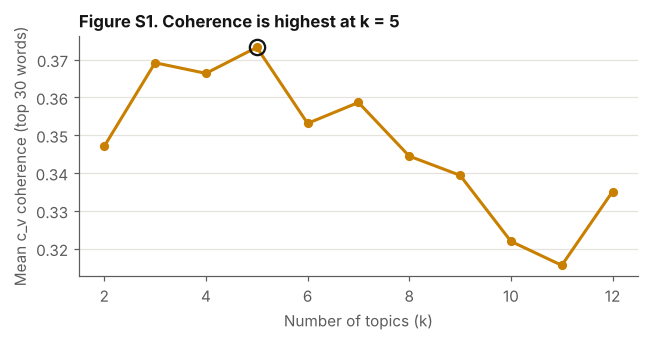

,k,c_v
0,2,0.3470
1,3,0.3691
2,4,0.3663
3,5,0.3732
4,6,0.3531
5,7,0.3586
6,8,0.3444
7,9,0.3394
8,10,0.3219
9,11,0.3156


In [3]:
coh = pd.DataFrame([{"k": k, "c_v": tp.coherence_cv(tp.fit_lda(X, k), vec, lemmas)} for k in range(2, 13)])
coh.round(4).to_csv(TAB / "S8_topic_coherence.csv", index=False)
best = int(coh.loc[coh.c_v.idxmax(), "k"])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(coh.k, coh.c_v, color=pf.PALETTE[0], lw=2, marker="o", ms=5)
ax.plot(best, coh.c_v.max(), "o", ms=10, mfc="none", mec=pf.INK, mew=1.5)
ax.set_xlabel("Number of topics (k)"); ax.set_ylabel("Mean c_v coherence (top 30 words)")
ax.set_title(f"Figure S1. Coherence is highest at k = {best}", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "FigS1_topic_coherence.png", dpi=300); fig.savefig(FIG / "FigS1_topic_coherence.pdf"); plt.show()
coh.round(4)

## Stability across random seeds (Supplementary Table S9)

In [4]:
stab = pd.concat([tp.seed_agreement(X, k) for k in (4, 5, 6)])
stab.to_csv(TAB / "S9_topic_stability.csv", index=False)
stab.groupby("k")["agreement_pct"].agg(["mean", "min", "max"]).round(1)

,mean,min,max
k,,,
4,60.4,52.2,67.5
5,59.7,51.2,68.1
6,59.3,53.4,63.3


## Rerun vs frozen 2024 assignment

In [5]:
frozen = pd.read_pickle(RAW / "topic_probability_2024.pkl").reset_index()[["Grant ID", "Topic N°"]]
lda5 = tp.fit_lda(X, 5)
rerun = pd.Series(lda5.transform(X).argmax(1), index=ids, name="rerun")
cmp = frozen.set_index("Grant ID")["Topic N°"].rename("frozen_2024").to_frame().join(rerun, how="inner")
xt = pd.crosstab(cmp.frozen_2024, cmp.rerun)
# Topic probabilities from the rerun, relabelled to the 2024 topic numbers (best one-to-one match),
# for the robustness check that splits each grant's amount across topics (notebook 06).
from scipy.optimize import linear_sum_assignment
r_idx, c_idx = linear_sum_assignment(-xt.values)
relabel = {xt.columns[c]: xt.index[r] for r, c in zip(r_idx, c_idx)}
probs = pd.DataFrame(lda5.transform(X), index=ids).rename(columns=relabel)
probs.columns = [f"p_topic_{k}" for k in probs.columns]
probs.index.name = "Grant ID"
probs.reset_index().to_csv(INTERIM / "topic_probabilities_rerun.csv", index=False)
print("rerun -> 2024 topic labels:", relabel, "| agreement after relabelling:",
      f"{sum(xt.loc[relabel[c], c] for c in xt.columns if c in relabel) / xt.values.sum() * 100:.1f}%")
xt

rerun -> 2024 topic labels: {np.int64(4): np.int64(0), np.int64(2): np.int64(1), np.int64(3): np.int64(2), np.int64(0): np.int64(3), np.int64(1): np.int64(4)} | agreement after relabelling: 59.1%


rerun,0,1,2,3,4
frozen_2024,,,,,
0,4,23,106,0,102
1,1,63,75,5,7
2,0,0,1,105,33
3,1,0,0,0,0
4,1,189,78,0,5


In [6]:
words = tp.top_words(lda5, vec, n=50)
words.to_csv(TAB / "S10_topic_top_words_rerun.csv", index=False)
words.head(15)

,topic_0,topic_1,topic_2,topic_3,topic_4
0,membrane,bacteriophage,infection,peptide,gene
1,antibacterial,bacteria,antibiotic,cell,cell
2,bacteria,treatment,bacteria,cancer,protein
3,negative,infection,resistance,antibody,bacteriophage
4,enzyme,therapy,bacterial,display,host
5,positive,bacterial,bacteriophage,target,bacterial
6,agent,strain,therapy,protein,study
7,resistant,resistant,resistant,vaccine,target
8,bacterial,antibiotic,pathogen,library,research
9,gene,control,system,bind,system


## Export the topic assignment used in the paper

In [7]:
frozen = frozen.rename(columns={"Topic N°": "topic_id"}).assign(source="lda_2024")
m = frozen.set_index("Grant ID")["topic_id"]
inherited = pd.DataFrame([{"Grant ID": g, "topic_id": m[o], "source": f"duplicate_of:{o}"}
                          for g, o in dup_of.items() if o in m.index])
assign = pd.concat([frozen, inherited], ignore_index=True)
assign.to_csv(INTERIM / "topic_assignments.csv", index=False)
print(len(assign), "grants with a topic;", len(inherited), "inherited from a duplicate text")
assign.topic_id.value_counts().sort_index()

818 grants with a topic; 19 inherited from a duplicate text


topic_id
0    243
1    152
2    140
3      1
4    282
Name: count, dtype: int64